In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("EDA Project Started Successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

EDA Project Started Successfully!
Pandas version: 3.0.3
NumPy version: 2.4.6


In [2]:
# Create a sample sales dataset
data = {
    "Order_ID": list(range(101, 121)),
    "Product": [
        "Laptop", "Phone", "Tablet", "Laptop", "Phone",
        "Tablet", "Laptop", "Phone", "Tablet", "Laptop",
        "Phone", "Tablet", "Laptop", "Phone", "Tablet",
        "Laptop", "Phone", "Tablet", "Laptop", "Phone"
    ],
    "Sales": [
        55000, 25000, 18000, 60000, 28000,
        20000, 52000, 30000, 19000, 65000,
        27000, 22000, 58000, 32000, 21000,
        62000, 26000, 24000, 57000, 29000
    ],
    "Quantity": [
        2, 3, 2, 1, 4, 3, 2, 2, 4, 1,
        3, 2, 2, 3, 2, 1, 4, 3, 2, 3
    ],
    "City": [
        "Hyderabad", "Vijayawada", "Chennai", "Hyderabad",
        "Vijayawada", "Chennai", "Hyderabad", "Chennai",
        "Vijayawada", "Hyderabad", "Chennai", "Vijayawada",
        "Hyderabad", "Chennai", "Vijayawada", "Hyderabad",
        "Chennai", "Vijayawada", "Hyderabad", "Chennai"
    ]
}

df = pd.DataFrame(data)

print("Sales dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head(10))

Sales dataset created successfully!
Dataset shape: (20, 5)


,Order_ID,Product,Sales,Quantity,City
0,101,Laptop,55000,2,Hyderabad
1,102,Phone,25000,3,Vijayawada
2,103,Tablet,18000,2,Chennai
3,104,Laptop,60000,1,Hyderabad
4,105,Phone,28000,4,Vijayawada
5,106,Tablet,20000,3,Chennai
6,107,Laptop,52000,2,Hyderabad
7,108,Phone,30000,2,Chennai
8,109,Tablet,19000,4,Vijayawada
9,110,Laptop,65000,1,Hyderabad


In [3]:
# 1. Display dataset information
print("Dataset Information:")
df.info()

# 2. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 4. Check data types
print("\nData Types:")
print(df.dtypes)

# 5. Display statistical summary
print("\nStatistical Summary:")
display(df.describe())

# 6. Display product counts
print("\nProduct Counts:")
print(df["Product"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Order_ID  20 non-null     int64
 1   Product   20 non-null     str  
 2   Sales     20 non-null     int64
 3   Quantity  20 non-null     int64
 4   City      20 non-null     str  
dtypes: int64(3), str(2)
memory usage: 1.2 KB

Missing Values:
Order_ID    0
Product     0
Sales       0
Quantity    0
City        0
dtype: int64

Duplicate Rows: 0

Data Types:
Order_ID    int64
Product       str
Sales       int64
Quantity    int64
City          str
dtype: object

Statistical Summary:


,Order_ID,Sales,Quantity
count,20.00000,20.000000,20.000000
mean,110.50000,36500.000000,2.450000
std,5.91608,17061.807148,0.944513
min,101.00000,18000.000000,1.000000
25%,105.75000,23500.000000,2.000000
50%,110.50000,28500.000000,2.000000
75%,115.25000,55500.000000,3.000000
max,120.00000,65000.000000,4.000000



Product Counts:
Product
Laptop    7
Phone     7
Tablet    6
Name: count, dtype: int64


In [4]:
# Statistical analysis of sales data

print("Total Sales:", df["Sales"].sum())
print("Average Sales:", round(df["Sales"].mean(), 2))
print("Highest Sale:", df["Sales"].max())
print("Lowest Sale:", df["Sales"].min())
print("Total Quantity Sold:", df["Quantity"].sum())

print("\nSales by Product:")
print(df.groupby("Product")["Sales"].sum().sort_values(ascending=False))

print("\nSales by City:")
print(df.groupby("City")["Sales"].sum().sort_values(ascending=False))

Total Sales: 730000
Average Sales: 36500.0
Highest Sale: 65000
Lowest Sale: 18000
Total Quantity Sold: 49

Sales by Product:
Product
Laptop    409000
Phone     197000
Tablet    124000
Name: Sales, dtype: int64

Sales by City:
City
Hyderabad     409000
Chennai       182000
Vijayawada    139000
Name: Sales, dtype: int64


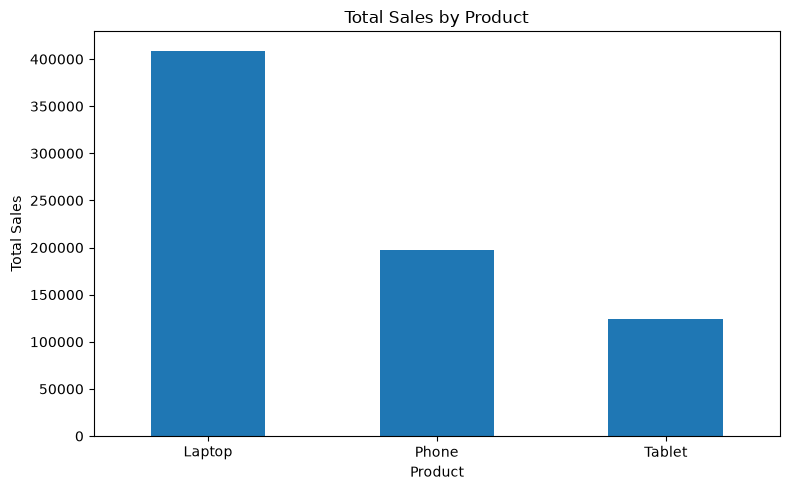

In [5]:
product_sales = df.groupby("Product")["Sales"].sum()

plt.figure(figsize=(8, 5))
product_sales.plot(kind="bar")
plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Total Sales by City:


City
Hyderabad     409000
Chennai       182000
Vijayawada    139000
Name: Sales, dtype: int64

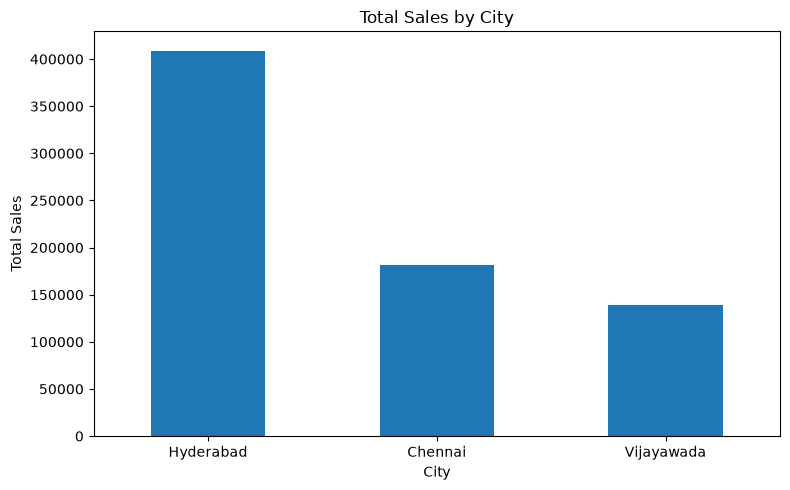

In [7]:
# Calculate total sales for each city
city_sales = df.groupby("City")["Sales"].sum().sort_values(
    ascending=False
)

print("Total Sales by City:")
display(city_sales)

# Create a bar chart
plt.figure(figsize=(8, 5))
city_sales.plot(kind="bar")
plt.title("Total Sales by City")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Correlation Matrix:


,Sales,Quantity
Sales,1.00000,-0.69402
Quantity,-0.69402,1.00000


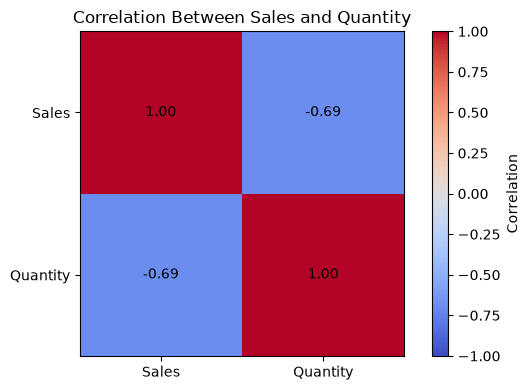

In [8]:
# Select numerical columns
numeric_df = df[["Sales", "Quantity"]]

# Calculate correlation
correlation = numeric_df.corr()

print("Correlation Matrix:")
display(correlation)

# Visualize the correlation matrix
plt.figure(figsize=(6, 4))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(len(correlation.columns)), correlation.columns)
plt.yticks(range(len(correlation.index)), correlation.index)

for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        plt.text(
            j, i, f"{correlation.iloc[i, j]:.2f}",
            ha="center", va="center"
        )

plt.title("Correlation Between Sales and Quantity")
plt.tight_layout()
plt.show()

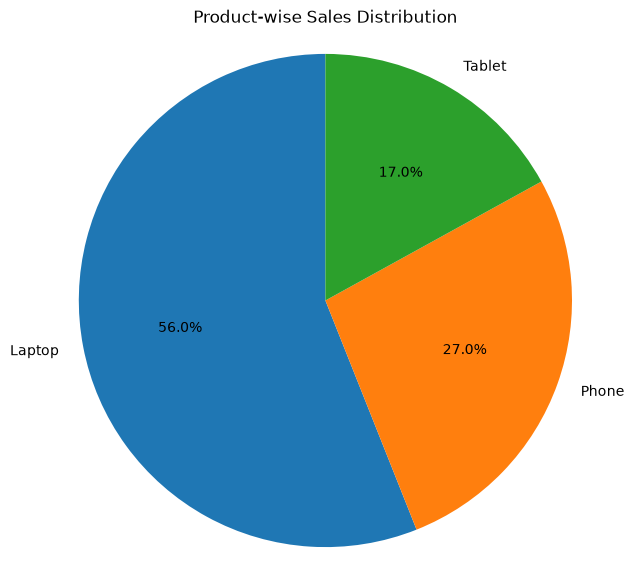

In [9]:
# Calculate total sales by product
product_sales = df.groupby("Product")["Sales"].sum()

# Create a pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    product_sales,
    labels=product_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Product-wise Sales Distribution")
plt.axis("equal")
plt.show()


In [10]:
# Generate key insights from the dataset
top_product = df.groupby("Product")["Sales"].sum().idxmax()
top_city = df.groupby("City")["Sales"].sum().idxmax()

print("========== EDA PROJECT INSIGHTS ==========")
print("1. Total Orders:", len(df))
print("2. Total Sales:", df["Sales"].sum())
print("3. Average Sale:", round(df["Sales"].mean(), 2))
print("4. Total Quantity Sold:", df["Quantity"].sum())
print("5. Top Product by Sales:", top_product)
print("6. Top City by Sales:", top_city)
print("7. Missing Values:", df.isnull().sum().sum())
print("8. Duplicate Rows:", df.duplicated().sum())
print("==========================================")

========== EDA PROJECT INSIGHTS ==========
1. Total Orders: 20
2. Total Sales: 730000
3. Average Sale: 36500.0
4. Total Quantity Sold: 49
5. Top Product by Sales: Laptop
6. Top City by Sales: Hyderabad
7. Missing Values: 0
8. Duplicate Rows: 0


In [11]:
# Generate a final Exploratory Data Analysis report

total_sales = df["Sales"].sum()
average_sales = df["Sales"].mean()
top_product = df.groupby("Product")["Sales"].sum().idxmax()
top_city = df.groupby("City")["Sales"].sum().idxmax()

report = f"""
========================================
EXPLORATORY DATA ANALYSIS REPORT
========================================

Project: Sales Data Analysis

1. DATASET OVERVIEW
Total Records: {len(df)}
Total Columns: {len(df.columns)}
Columns: {", ".join(df.columns)}

2. DATA QUALITY
Missing Values: {df.isnull().sum().sum()}
Duplicate Rows: {df.duplicated().sum()}

3. SALES SUMMARY
Total Sales: {total_sales:,.2f}
Average Sale: {average_sales:,.2f}
Highest Sale: {df["Sales"].max():,.2f}
Lowest Sale: {df["Sales"].min():,.2f}
Total Quantity Sold: {df["Quantity"].sum()}

4. KEY FINDINGS
Top Product by Sales: {top_product}
Top City by Sales: {top_city}

5. VISUALIZATIONS CREATED
- Total Sales by Product
- Total Sales by City
- Correlation Matrix
- Product-wise Sales Distribution

6. CONCLUSION
This analysis explored the sample sales dataset using
Pandas, NumPy and Matplotlib. The visualizations helped
compare products, cities and sales patterns.

Note: This is sample data created for learning purposes.
The findings do not represent actual business performance.
========================================
"""

print(report)


EXPLORATORY DATA ANALYSIS REPORT

Project: Sales Data Analysis

1. DATASET OVERVIEW
Total Records: 20
Total Columns: 5
Columns: Order_ID, Product, Sales, Quantity, City

2. DATA QUALITY
Missing Values: 0
Duplicate Rows: 0

3. SALES SUMMARY
Total Sales: 730,000.00
Average Sale: 36,500.00
Highest Sale: 65,000.00
Lowest Sale: 18,000.00
Total Quantity Sold: 49

4. KEY FINDINGS
Top Product by Sales: Laptop
Top City by Sales: Hyderabad

5. VISUALIZATIONS CREATED
- Total Sales by Product
- Total Sales by City
- Correlation Matrix
- Product-wise Sales Distribution

6. CONCLUSION
This analysis explored the sample sales dataset using
Pandas, NumPy and Matplotlib. The visualizations helped
compare products, cities and sales patterns.

Note: This is sample data created for learning purposes.
The findings do not represent actual business performance.



In [12]:
with open("EDA_Final_Report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print("Final EDA report saved successfully!")

Final EDA report saved successfully!
